# Model M2: verifier slots and the 30 September deadline

M2 takes one compliance year and adds the practical limits. For 2026 data, verification must happen between January and the declaration deadline of 30 September 2027 (39 weeks).

- At most **K** verifications can run at once.
- Each verification takes an uncertain number of weeks: 6, 8 or 12 on average for small, medium and large installations, including the wait for a verifier.
- A supplier may be verified **before** its customer's result is in. This is faster, but the cost is wasted if the customer fails or its result is withheld.
- A result is opened when its customer's data are in use. The exporter then uses or withholds it, as in M0. Anything not in use by the deadline counts for nothing.

The trees are small, so the optimal policy is found exactly by dynamic programming over the status of every node and the week. Two simple policies are compared with it:
- **sequential**: verify a node only after its customer's data are in use;
- **speculative** (the parallel rule in the paper): start every node M0 would verify as soon as a slot is free.

Both rank nodes by their M0 value per expected week.

Values are expected net savings for the compliance year in euros, relative to staying on defaults. The comparison point is M0, which has no slot limit and no deadline.

In [1]:
import subprocess, sys
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.max_columns", 30, "display.width", 200)
print(subprocess.run([sys.executable, "scripts/run_m2.py"], cwd=ROOT, capture_output=True, text=True, check=True).stdout)
grid = pd.read_csv(ROOT / "Data/results/m2_grid.csv")
usage = pd.read_csv(ROOT / "Data/results/m2_usage.csv")

M2 solved for 384 settings
  T1 2026 K=1: optimal EUR  3,779,212 (M0  4,589,924) | sequential gap 0.7% | speculative gap 0.7% | wasted EUR 55,592
  T1 2026 K=2: optimal EUR  4,330,401 (M0  4,589,924) | sequential gap 4.6% | speculative gap 0.0% | wasted EUR 43,965
  T1 2030 K=1: optimal EUR  6,935,747 (M0  8,388,392) | sequential gap 0.8% | speculative gap 0.8% | wasted EUR 54,953
  T1 2030 K=2: optimal EUR  7,933,405 (M0  8,388,392) | sequential gap 4.6% | speculative gap 0.0% | wasted EUR 43,174
  T2 2026 K=1: optimal EUR          0 (M0          0) | sequential gap % | speculative gap % | wasted EUR 0
  T2 2026 K=2: optimal EUR          0 (M0          0) | sequential gap % | speculative gap % | wasted EUR 0
  T2 2030 K=1: optimal EUR  1,479,949 (M0  1,420,016) | sequential gap 15.2% | speculative gap 0.2% | wasted EUR 23,009
  T2 2030 K=2: optimal EUR  1,526,649 (M0  1,420,016) | sequential gap 15.8% | speculative gap 3.6% | wasted EUR 31,874
  T3 2026 K=1: optimal EUR  2,148,853 (M0

## 1. Full window (39 weeks), central verification times

In [2]:
b = grid[(grid.window_weeks == 39) & (grid.duration_scale == 1.0) & (grid.value_m0_no_limits > 0)].copy()
b["optimal €k"] = (b.value_optimal / 1e3).round(0).astype(int)
b["M0 €k"] = (b.value_m0_no_limits / 1e3).round(0).astype(int)
b = b.rename(columns={"pct_of_m0": "% of M0", "scarcity_cost_eur_per_t": "cost of limits €/t",
                      "gap_sequential_pct": "sequential gap %", "gap_speculative_pct": "speculative gap %",
                      "wasted_spend": "wasted spend €"})
b.set_index(["tree", "year", "slots"])[["optimal €k", "M0 €k", "% of M0", "cost of limits €/t",
                                         "sequential gap %", "speculative gap %", "wasted spend €"]]

optimal €k  M0 €k  % of M0  cost of limits €/t  sequential gap %  speculative gap %  wasted spend €
tree year slots                                                                                                     
T1   2026 1            3779   4590     82.3              16.214               0.7                0.7           55592
          2            4330   4590     94.3               5.190               4.6                0.0           43965
          3            4373   4590     95.3               4.341               5.5                0.0           48425
          4            4373   4590     95.3               4.341               5.5                0.0           48425
     2030 1            6936   8388     82.7              29.053               0.8                0.8           54953
          2            7933   8388     94.6               9.100               4.6                0.0           43174
          3            8015   8388     95.5               7.473               5.6                0.0           47621
          4            8015   8388     95.5               7.473               5.6                0.0           47621
T2   2030 1            1480   1420    104.2              -1.199              15.2                0.2           23009
          2            1527   1420    107.5              -2.133              15.8                3.6           31874
          3            1528   1420    107.6              -2.154              15.9                3.7           31417
          4            1528   1420    107.6              -2.154              15.9                3.7           31412
T3   2026 1            2149   2539     84.6               7.805               0.0                0.0           54525
          2            2398   2539     94.4               2.827               4.6                0.0           60689
          3            2410   2539     94.9               2.586               5.1                0.0           65592
          4            2410   2539     94.9               2.586               5.1                0.0           65592
     2030 1            5365   6295     85.2              18.590               0.2                0.2           59540
          2            5978   6295     95.0               6.340               4.7                0.0           49200
          3            6015   6295     95.6               5.587               5.3                0.0           53803
          4            6015   6295     95.6               5.587               5.3                0.0           53803
T4   2026 1            1742   1808     96.4               6.526               0.0                0.0           32463
          2            1774   1808     98.2               3.330               0.6                0.0           35053
          3            1775   1808     98.2               3.266               0.6                0.0           34520
          4            1775   1808     98.2               3.266               0.6                0.0           34520
     2030 1            3160   3302     95.7              14.222               0.0                0.0           26412
          2            3245   3302     98.3               5.683               1.1                0.2           29526
          3            3247   3302     98.3               5.533               1.1                0.0           30012
          4            3247   3302     98.3               5.533               1.1                0.0           30012

- With one slot, the steel trees with large suppliers lose 15–18% of the value: €16 per tonne exported in T1 in 2026, €29 in 2030. A second slot recovers most of it; more slots add almost nothing here.
- The sequential policy, which waits for each customer's result, loses about 5% in T1 and T3 and about 15% in T2 even with ample slots, and with a short window it can end in a loss (section 3). The speculative policy, which verifies suppliers in parallel, is within 1% of the optimum in 83% of the settings tried.
- In T2 (India, 2030) the optimal policy with limits does better than M0. Starting the DRI plant's verification alongside the billet maker's means the DRI result is often known before the billet maker's data must be used or withheld, which M0's one-node-at-a-time sequence cannot do. The price is some wasted spend (last column).

## 2. Value against the length of the window

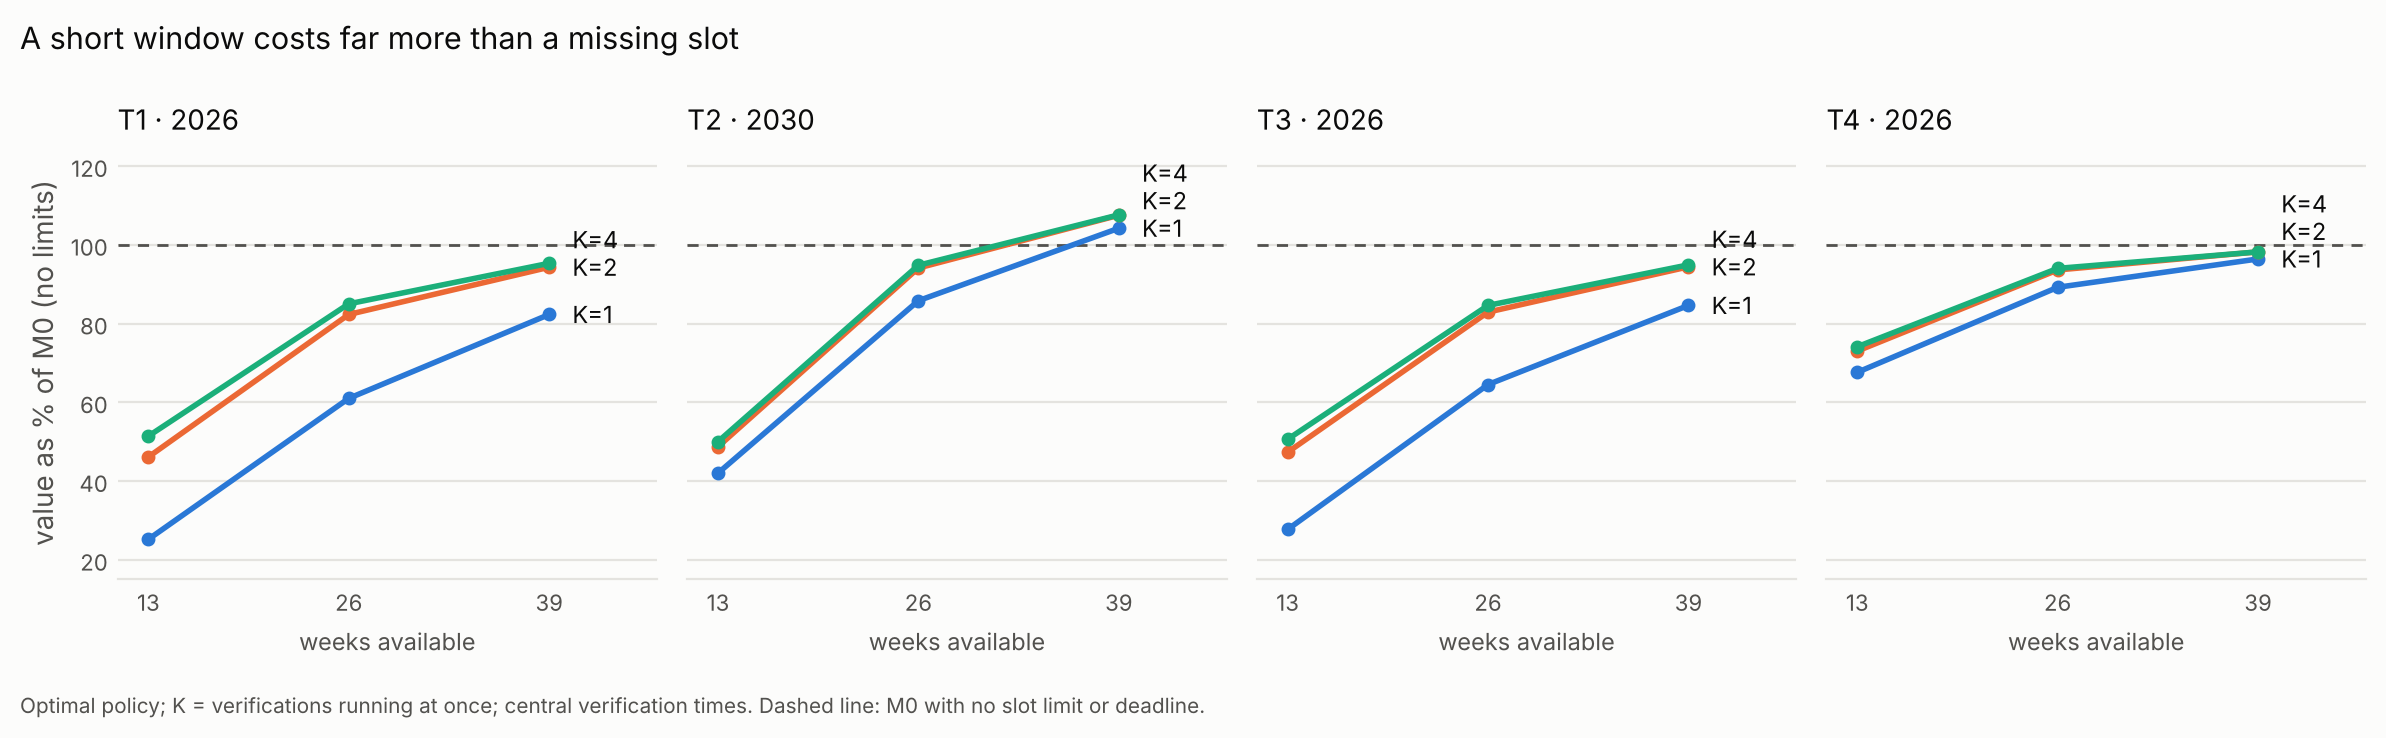

In [3]:
import matplotlib.pyplot as plt

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COL = {1: "#2a78d6", 2: "#eb6834", 4: "#1baf7a"}
cases = [("T1", 2026), ("T2", 2030), ("T3", 2026), ("T4", 2026)]
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4), sharey=True, facecolor=SURFACE)
for ax, (tid, y) in zip(axes, cases):
    g = grid[(grid.tree == tid) & (grid.year == y) & (grid.duration_scale == 1.0)]
    ax.set_facecolor(SURFACE)
    ax.axhline(100, color=INK2, lw=1, ls=(0, (4, 3)))
    ends = []
    for K, c in COL.items():
        h = g[g.slots == K].sort_values("window_weeks")
        ax.plot(h.window_weeks, h.pct_of_m0, color=c, lw=2, marker="o", ms=4)
        ends.append([h.pct_of_m0.iloc[-1], f"K={K}", c])
    ends.sort()
    for k in range(1, len(ends)):
        ends[k][0] = max(ends[k][0], ends[k - 1][0] + 7)
    for yv, lab, c in ends:
        ax.annotate(lab, (40.5, yv), fontsize=8.5, color=INK, va="center")
    ax.set_title(f"{tid} · {y}", loc="left", fontsize=10, color=INK)
    ax.set_xticks([13, 26, 39]); ax.set_xlim(11, 46); ax.set_ylim(15, 125)
    ax.set_xlabel("weeks available", color=INK2, fontsize=8.5)
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ["top", "right", "left"]: ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID); ax.tick_params(colors=INK2, length=0, labelsize=8)
axes[0].set_ylabel("value as % of M0 (no limits)", color=INK2)
fig.suptitle("A short window costs far more than a missing slot", x=0.01, ha="left", fontsize=11, color=INK)
fig.text(0.01, -0.04, "Optimal policy; K = verifications running at once; central verification times. Dashed line: M0 with no slot limit or deadline.",
         fontsize=7.5, color=INK2)
fig.tight_layout(); plt.show()

## 3. How the simple policies fare across all 336 settings with positive value

In [4]:
g = grid[grid.value_optimal > 0]
summary = g.groupby("tree")[["gap_sequential_pct", "gap_speculative_pct"]].agg(["mean", "max"]).round(1)
summary.columns = ["sequential gap % (mean)", "sequential gap % (max)", "speculative gap % (mean)", "speculative gap % (max)"]
print(f"speculative within 1% of optimal in {100 * (g.gap_speculative_pct <= 1).mean():.0f}% of settings; "
      f"sequential in {100 * (g.gap_sequential_pct <= 1).mean():.0f}%; sequential loses money in {(g.value_sequential < 0).sum()} settings")
summary

speculative within 1% of optimal in 83% of settings; sequential in 21%; sequential loses money in 8 settings


,sequential gap % (mean),sequential gap % (max),speculative gap % (mean),speculative gap % (max)
tree,,,,
T1,17.2,49.5,2.0,30.5
T2,49.7,116.0,4.2,24.6
T3,15.2,45.2,0.5,8.5
T4,3.1,9.7,0.3,3.8


## 4. Which suppliers drop out when time runs short (one slot)

In [5]:
u = usage[(usage.slots == 1) & (usage.duration_scale == 1.0) &
          (((usage.tree == "T2") & (usage.year == 2030)) | ((usage.tree != "T2") & (usage.year == 2026)))]
u.pivot_table(index=["tree", "node"], columns="window_weeks", values="p_in_use", sort=False).round(2)

window_weeks    13    26    39
tree node                     
T1   R        0.32  0.64  0.80
     M1       0.31  0.60  0.73
     M2       0.10  0.36  0.58
T2   R        0.40  0.69  0.78
     DRI      0.29  0.51  0.59
     PEL      0.10  0.31  0.43
     PIG      0.08  0.31  0.48
T3   R        0.32  0.64  0.89
     EAF      0.31  0.61  0.74
     BF       0.07  0.28  0.45
T4   R        0.74  0.87  0.90
     PRI      0.12  0.41  0.59
     SEC      0.47  0.73  0.79

The table gives the probability that each installation's data are in use at the deadline. As the window shrinks, the exporter's own installation stays the most likely to be in use, because it unlocks everything else. The supplier dropped first is the one with less value per week: mill B in T1, the BF-BOF mill in T3, and the pellet plant and pig-iron supplier in T2.

## Tests and caveats

- `tests/test_m2.py` checks that:
  - with fast verifications, many slots and a long window, the sequential policy reproduces M0;
  - under those conditions the optimal policy is never worse than M0, and it is never worse than either simple policy;
  - value never falls with more slots or a longer window;
  - simulating the optimal policy matches both its value and the probabilities in the table above.
- **Durations** are geometric (memoryless) in weeks, a deliberately wide spread. A result that arrives early is held until its customer's data are in use; its emissions are not used to decide about the customer. Allowing that would make parallel verification even more valuable.
- **Slots** are verifications available to this one supply chain. Competition for verifiers across many declarants (403 verifiers for 4,100 declarants) is a market question left for future work.